![](docs/Banner.jpg)

# InSAR Time Series Analysis: MintPy + NISAR GUNW products

Modified for Track and Frame 034_A_019 ARSET Training Eric Fielding November 2026

**Author:** Changyang Hu, Zhang Yunjun, Heresh Fattahi, August 3-7, 2026 [EarthScope InSAR Short Course (ISCE+)](https://www.earthscope.org/event/2026-technical-course-insar-processing-and-analysis-isce/).

The Miami INsar Timeseries software in PYthon (MintPy) is an open-source package for InSAR time-series analysis. MintPy currently starts from stacks of unwrapped interferograms (in either geo- or radar-coordinates) and estimates ground displacement time-series. MintPy is primarily consistent with stacks of interferograms processed with ISCE. However, the software also supports interfarograms processed with other InSAR processors such as GAMMA, GMTSAR, SNAP and ROI_PAC. 

MintPy is available on Github from the following page: https://github.com/insarlab/MintPy

References: The detailed algorithms implemented in MintPy can be found in the following paper: 

+ Yunjun, Z., Fattahi, H., Amelung, F. (2019), Small baseline InSAR time series analysis: Unwrapping error correction and noise reduction, _Computers & Geosciences, 133,_ 104331. [ [doi](https://doi.org/10.1016/j.cageo.2019.104331) \| [arxiv](https://doi.org/10.31223/osf.io/9sz6m) \| [data](https://doi.org/10.5281/zenodo.3464190) \| [notebook](https://github.com/geodesymiami/Yunjun_et_al-2019-MintPy) ]

# Table of Contents

1. [Initial setup](#id-1-initial-setup-of-the-notebook)
2. [Download pre-processed interferograms](id-2-download-pre-processed-interferograms)
3. [Overview of `smallbaselineApp`](#id-3-general-overview-of-smallbaselineapp-py)
4. [Time series analysis](#id-4-time-series-analysis)

# 1. Initial setup of the notebook

The cell below performs the intial setup of the notebook and must be **run every time the notebook (re)starts**. It defines the processing location and check the example dataset.

In [1]:
%matplotlib inline
import os
import shutil
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import mintpy
import numpy as np
from mintpy.cli import view, tsview, plot_network, plot_transection
plt.rcParams.update({'font.size': 12})

import NISAR_utils as ut

# define directory structure
# $HOME/Downloads/NISAR_training
# change to your preferred location
work_dir = Path.home() / "Downloads" / "NISAR_training" / "LosAngeles_NI_A34" / "mintpy"
ifg_dir = work_dir.parent / "interferograms"               # downloaded NISAR GUNW directory
dem_file = work_dir.parent / "DEM" / "cop_dem.tif"         # DEM file path
cfg_file = work_dir / f"{work_dir.parent.name}.txt"        # mintpy configuration file path

# go to work directory
os.makedirs(work_dir, exist_ok=True)
os.chdir(work_dir)
print('Go to work directory:', work_dir)

# check mintpy version
print('mintpy version:', mintpy.__version__, ', released at', mintpy.version.version_date)
if mintpy.__version__ < "1.6.4":
    msg = 'mintpy-1.6.4 or newer is required!'
    msg += '\nGo to ~/conda_environments/Create_OSL_Pixi_Environments.ipynb '
    msg += 'and re-create the "earthscope_insar_env" environment.'
    raise ValueError(msg)

Go to work directory: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy
mintpy version: 1.6.4 , released at 2026-07-25


# 2. Download pre-processed interferograms

## 2.1 Download NISAR GUNW products from ASF

Search and download NISAR Level-2 GUNW products from [ASF Data Search](https://search.asf.alaska.edu/#/) using [`asf_search`](https://nisar-docs.asf.alaska.edu/asf-search/). Authentication uses Earthdata Login credentials from `~/.netrc`.

This example uses Los Angeles, ascending track **034**, frame **019**. Products are saved to `~/Downloads/NISAR_training/LosAngeles_NI_A34/interferograms` in this example.

In [2]:
# download NISAR GUNW from ASF
start_date = '20251001'
end_date = '20261001'
wsen = (-120.6, 34.0, -117.0, 35.5)
track_frame = '034_A_019'
flight_direction = 'ASCENDING'

ut.download_nisar_gunw(
    ifg_dir=ifg_dir,
    wsen=wsen,
    start_date=start_date,
    end_date=end_date,
    short_name="NISAR_L2_GUNW_PROVISIONAL_V1",   # or "NISAR_L2_GUNW_PROVISIONAL_V1"
    flight_direction=flight_direction,
    track_frame=track_frame,
    product_type="GUNW",
    use_existing_data=False,
)
print('Complete GUNW files downloading.')

POLYGON ((-120.6 34.0, -116.0 34.0, -116.0 35.5, -120.6 35.5, -120.6 34.0))
Found 25 GUNW products:
['https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GUNW_PROVISIONAL_V1/NISAR_L2_PR_GUNW_006_034_A_019_007_4000_SH_20251124T130824_20251124T130859_20251206T130825_20251206T130900_P05023_N_F_J_001/NISAR_L2_PR_GUNW_006_034_A_019_007_4000_SH_20251124T130824_20251124T130859_20251206T130825_20251206T130900_P05023_N_F_J_001.h5',
 'https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GUNW_PROVISIONAL_V1/NISAR_L2_PR_GUNW_007_034_A_019_008_4000_SH_20251206T130825_20251206T130900_20251218T130826_20251218T130900_P05023_N_F_J_001/NISAR_L2_PR_GUNW_007_034_A_019_008_4000_SH_20251206T130825_20251206T130900_20251218T130826_20251218T130900_P05023_N_F_J_001.h5',
 'https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GUNW_PROVISIONAL_V1/NISAR_L2_PR_GUNW_008_034_A_019_009_4000_SH_20251218T130826_20251218T130900_20251230T130826_20251230T130901_P05023_N_F_J_001/NISAR_L2_PR_GUNW_008_034_A_019_00

## 2.2 Download DEM

Download the Copernicus DEM via `sardem`. This program can be installed with `conda install sardem -c conda-forge`

In [32]:
dem_file.parent.mkdir(parents=True, exist_ok=True)
dem_wsen = '-121 33 -117 36'  # use a large AOI that includes the entire NISAR GUNW product
!sardem --bbox {dem_wsen} --output-type float32 --output-format GTiff --data-source COP -o {dem_file}


[11/18 13:42:01] [INFO dem.py] Bounds: -121.0 33.0 -116.0 36.0
[11/18 13:42:01] [INFO cop_dem.py] Creating /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/DEM/cop_dem.tif
[11/18 13:42:01] [INFO cop_dem.py] Fetching remote tiles...
[11/18 13:42:01] [INFO cop_dem.py] Running GDAL command:
[11/18 13:42:01] [INFO cop_dem.py] gdalwarp /vsicurl/https://raw.githubusercontent.com/scottstanie/sardem/master/sardem/data/cop_global.vrt /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/DEM/cop_dem.tif -of GTiff -ot Float32 -te -121.000138888888884 32.9998611111111089 -115.999861111111116 36.0001388888888911 -tr 0.000277777777777777778 0.000277777777777777778 -s_srs "epsg:4326+3855" -t_srs "epsg:4326" -wo NUM_THREADS=4 -r nearest -wm 5000 -multi
Creating output file that is 18001P x 10801L.
]9;4;1;2]9;4;1;5]9;4;1;7]9;4;1;10]9;4;1;12]9;4;1;15]9;4;1;17]9;4;1;20]9;4;1;22]9;4;1;25]9;4;1;27]9;4;1;30]9;4;1;32]9;4;1;35]9;4;1;37]9;4;1;40]9;4;1;42]9;4;1;

# 3. General overview of smallbaselineApp.py

This application provides a workflow which includes several steps to invert a stack of unwrapped interferograms and apply different corrections to obtain ground displacement timeseries. The workflow consists of two main blocks:

* correcting for unwrapping errors and inverting for the raw phase time-series (blue ovals)
* correcting for noise from different sources to obtain the displacement time-series (green ovals)

Some steps are optional, which are switched off by default (marked by dashed boundaries). Configuration parameters for each step are initiated with default values in a customizable text file: [smallbaselineApp.cfg](https://github.com/insarlab/MintPy/blob/main/src/mintpy/defaults/smallbaselineApp.cfg). In this notebook, we will walk through the various steps.

![](docs/smallbaselineApp_workflow.jpg)
<p style="text-align: center;">
    (Figure from Yunjun et al., 2019)
</p>

## 3.1 Processing steps of smallbaselineApp.py

The `smallbaselineApp.py` workflow can be called with a single command-line call. By default it will run all the required processing steps with options pulled from the template files, as shown in [section 5.2](#5.2-smallbaselineApp.py-non-stop-processing). However, in this notebook, we will use the "step" processing, which allows to re-start the processing from a given step. More detailed usage can be found in help.

In [33]:
!smallbaselineApp.py --help

usage: smallbaselineApp.py [-h] [--dir WORKDIR] [-g] [-H] [-v] [--plot]
                           [--start STEP] [--end STEP] [--dostep STEP]
                           [customTemplateFile]

Routine Time Series Analysis for Small Baseline InSAR Stack

positional arguments:
  customTemplateFile    custom template with option settings.
                        ignored if the default smallbaselineApp.cfg is input.

options:
  -h, --help            show this help message and exit
  --dir, --work-dir WORKDIR
                        work directory, (default: ./).
  -g                    generate default template (if it does not exist) and exit.
  -H                    print the default template file and exit.
  -v, --version         print software version and exit
  --plot                plot results [only] without running smallbaselineApp.

steps processing (start/end/dostep):
  Command line options for steps processing with names chosen from the following list:
  
  ['load_data', 'modify_n

The app includes the following processing steps:

**Input:**

* `load_data:` loads the stack of interferograms (unwrapped phase, coherence, and/or connected componenents) and geometry files (height, incidence/azimuth angle, lookup tables etc.) into HDF5 files with multiple datasets and attributes.  

**Network inversion for time-series:**

* `modify_network:` this step (if requested) modifies the network of interferograms, e.g., based on average coherence, temporal and spatial baselines threshold, or by removing specific pairs.
* `reference_point:` the unwrapped interferograms may be relative to differnt reference pixels. This step introduces a common reference pixel to all interferograms. For intuitive interpretation, one may choose a stable coherent non-deforming pixel. However, since the estimated InSAR displacement time-series is relative in both time and space, choosing a deforming pixel does not change the results.
* `quick_overview:` this step provides a quick assessment of:
   1. expected rate maps even before inversion by simply averaging / stacking the unwrapped interferograms;
   2. distribution of unwrapping errors from the number of interferogram triplets with non-zero integer ambiguity.
* `correct_unwrap_error:` the input unwrapped interferograms may be affected by phase unwrapping errors (wrong integer number of $2\pi$ phase added during phase unwrapping). This step (if requested) offers three methods to possibly correct unwrapping errors.
* `invert_network:` inverts the stack of unwrapped interferograms to form the InSAR phase time-series. This is equivalent to transforming the network of small-baseline interferograms to a single-reference network of interferogram (i.e., the unwrapped phase timeseries). 

**Noise reduction of displacement time-series:**

* `correct_LOD:` this step is specific to Envisat data and applies an empircal correction to account for possible local oscilator drift of the radar.
* `correct_SET:` corrects (if requested) the solid Earth tides due to the gravity pull from the Sun and the Moon.
* `correct_ionosphere`: corrects ionospheric delay using the split-spectrum results (from ISCE-2 stack processors only).
* `correct_troposphere:` corrects tropospheric delay 1) using atmospheric models or 2) with empirical phase elevation approach estimated from InSAR data.
* `deramp:` this step (if requested) removes a ramp from each acquisition. Note that deramping removes residual long-wavelength interferometric phase components which may be due to noise (geometrical residual, atmospheric delay) or signal (tectonic deformation).  
* `correct_topography:` estimates residual topographic effects (due to DEM errors) which are correlated with temporal variation of perpendicular baseline.  
* `residual_RMS:` estimates the average noise level for each acquisition by calculating the RMS of the residual phase.
* `reference_date:` change reference date.
* `velocity:` estimates a suite of time functions, such as a linear velocity.

**Output:**

* `geocode:` if the original stack in radar-coordinates, convert it to geo-coordinates in lat/lon
* `google_earth:` output the average velocity into an Google Earth KMZ file.
* `hdfeos5:` output the displacement time-series with geometry info into one file in [HDF-EOS5](http://hdfeos.org) format.

## 3.2 Configuring the processing parameters

The processing parameters for the smallbaselineApp.py are controlled via configuration files. At least one file is required to run smallbaselineApp.py.

* `default configuration`: [smallbaselineApp.cfg](https://github.com/insarlab/MintPy/blob/main/src/mintpy/defaults/smallbaselineApp.cfg). It contains all configuration parameters, grouped by steps, with default auto values (which are defined in [smallbaselineApp_auto.cfg](https://github.com/insarlab/MintPy/blob/main/src/mintpy/defaults/smallbaselineApp_auto.cfg)). This file is copied over to the current working directory and read every time smallbaselineApp.py runs.
* `custom configuration` (optional but recommended): `MexicoCity_NI_D113.txt` in the example dataset. It constains selective, manually modified configuration parameters. The custom template file name is arbitrary. Custom template has higher priority than the default template; if custom template is specified, smallbaselineApp.py will update the default smallbaselineApp.cfg file accordingly.

**Custom configuration for the dataset in this notebook**

Run the following to create an text file named _LosAngeles_NI_A34.txt_ with the following few lines in it in the _mintpy_ directory:

In [34]:
CONFIG_TXT = f'''# vim: set filetype=cfg:
mintpy.load.processor      = nisar  #[isce, aria, hyp3, gmtsar, snap, gamma, roipac, nisar], auto for isce
#---------interferogram datasets:
mintpy.load.unwFile        = {str(ifg_dir)}/NISAR*.h5
mintpy.load.corFile        = auto
mintpy.load.connCompFile   = auto
#---------geometry datasets:
mintpy.load.demFile        = {str(dem_file)}
mintpy.load.incAngleFile   = auto
mintpy.load.azAngleFile    = auto
mintpy.load.waterMaskFile  = auto

mintpy.reference.lalo           = 34.20, -118.17
mintpy.reference.date = 20251206   #[reference_date.txt / 20090214 / no], auto for reference_date.txt
mintpy.troposphericDelay.method = opera
mintpy.deramp                   = no
mintpy.topographicResidual      = no
mintpy.ionosphericDelay.method  = split_spectrum

# options to speedup the processing (fast but not the best)
mintpy.networkInversion.weightFunc           = no
mintpy.topographicResidual.pixelwiseGeometry = no
'''

ut.write_config_file(cfg_file, CONFIG_TXT, mode='w')

write configuration to file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/LosAngeles_NI_A34.txt


<div class="alert alert-warning">
<b>Notes:</b> 
The input of MintPy is a stack of interferograms. The multiple pairs of Sentinel-1 interferograms produced by topsApp.py is NOT a stack.
Standard NISAR GUNW products are a coregistered stack.
</div>

![](docs/ifgram_stack.jpg)

Check **more example datasets** from various InSAR processors at:
+ https://mintpy.readthedocs.io/en/latest/demo_dataset/

Check **more example file structures and template setups** from various InSAR processors at:
+ https://mintpy.readthedocs.io/en/latest/dir_structure/

# 4. Time series analysis

## 4.1 Load the NISAR GUNW products into MintPy

MintPy is most consistent with the ISCE2 and ISCE3 direct outputs. However, it supports interferograms processed with other InSAR software including Gamma and SNAP. In this tutorial we are using the NISAR GUNW products from ISCE3.

In [35]:
!smallbaselineApp.py {cfg_file} --dostep load_data


MintPy version 1.6.4, date 2026-07-25
--RUN-at-2026-11-18 13:47:11.403005--
Current directory: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy
Run routine processing with smallbaselineApp.py on steps: ['load_data']
Remaining steps: ['modify_network', 'reference_point', 'quick_overview', 'correct_unwrap_error', 'invert_network', 'correct_LOD', 'correct_SET', 'correct_ionosphere', 'correct_troposphere', 'deramp', 'correct_topography', 'residual_RMS', 'reference_date', 'velocity', 'geocode', 'google_earth', 'hdfeos5']
--------------------------------------------------
Project name: LosAngeles_NI_A34
Go to work directory: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy
read custom template file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/LosAngeles_NI_A34.txt
update default template based on input custom template
No new option value found, skip updating /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/smallbaseline

By running this command, the "inputs" directory inside the working directory is created and two HDF5 files are produced as

In [36]:
ls -l inputs

total 26510832
-rw-r--r--  1 fielding  staff   317477392 Nov 18 13:47 geometryGeo.h5
-rw-r--r--  1 fielding  staff  3760159419 Nov 18 13:49 ifgramStack.h5
-rw-r--r--  1 fielding  staff  3760159419 Nov 18 13:49 ionStack.h5
-rw-r--r--  1 fielding  staff        1058 Nov 18 13:47 LosAngeles_NI_A34.txt
-rw-r--r--  1 fielding  staff  1941506760 Nov 18 12:55 OPERA.h5
-rw-r--r--  1 fielding  staff  1866839480 Nov 18 13:49 setStack.h5
-rw-r--r--  1 fielding  staff       25168 Oct 18 13:37 smallbaselineApp.cfg
-rw-r--r--  1 fielding  staff  1866839480 Nov 18 13:49 tropoStack.h5


+ `ifgramStack.h5:` this file contains 6 dataset cubes and multiple metadata.

```
unwrapPhase      - 3D array in size of (m, l, w) for unwrapped interferometric phases data cube in radians
coherence        - 3D array in size of (m, l, w) for spatial coherence                data cube
connectComponent - 3D array in size of (m, l, w) for connected commponents            data cube
date             - 2D array in size of (m, 2) in YYYYMMDD format for the reference / secondary dates.
bperp            - 1D array in size of (m,) in meters for perpendicular baselines (average value)
dropIfgram       - 1D array in size of (m,) in boolean to indicate whether an interferogram is used for inversion or ignored
```

where `m` is the number of interferograms, `l` is the number of lines and `w` is the number of columns.

+ `geometryGeo.h5:` this file contains geometrical datasets including height, incidence angle, azimuth angle, shadow layover mask, slant range distance and/or water mask. 

Check more detailed description of the data structure [here](https://mintpy.readthedocs.io/en/latest/api/data_structure/).

<div class="alert alert-info">
<b>info.py:</b> 
To get general infomation about a MintPy product, run info.py on the file. Similar to "gdalinfo".   
</div>

In [37]:
# !gdalinfo inputs/geometryGeo.h5
!info.py inputs/geometryGeo.h5

******************** Basic File Info ************************
file name: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/inputs/geometryGeo.h5
file type: geometry
coordinates : GEO
SNWE: 3664080.0, 4006800.0, 146880.0, 494640.0.

******************** HDF5 File Structure ********************
Attributes in / level:
  ALOOKS                16
  AZIMUTH_PIXEL_SIZE    80.0
  CENTER_LINE_UTC       47321.999671
  EARTH_RADIUS          6371008.8
  EPSG                  32611
  FILE_TYPE             geometry
  HEIGHT                747000
  LENGTH                4284
  ORBIT_DIRECTION       Ascending
  PLATFORM              NISAR
  POLARIZATION          HH
  RANGE_PIXEL_SIZE      80.0
  RLOOKS                13
  STARTING_RANGE        889235.8125
  SUBSET_XMAX           4347
  SUBSET_XMIN           0
  SUBSET_YMAX           4284
  SUBSET_YMIN           0
  UTM_ZONE              11N
  WAVELENGTH            0.2419632429378531
  WIDTH                 4347
  XMAX                  

In [38]:
!info.py inputs/ifgramStack.h5

******************** Basic File Info ************************
file name: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/inputs/ifgramStack.h5
file type: ifgramStack
coordinates : GEO
SNWE: 3664080.0, 4006800.0, 146880.0, 494640.0.

******************** HDF5 File Structure ********************
Attributes in / level:
  ALOOKS                                          16
  AZIMUTH_PIXEL_SIZE                              80.0
  CENTER_LINE_UTC                                 47321.999671
  EARTH_RADIUS                                    6371008.8
  EPSG                                            32611
  FILE_TYPE                                       ifgramStack
  HEIGHT                                          747000
  LENGTH                                          4284
  ORBIT_DIRECTION                                 Ascending
  PLATFORM                                        NISAR
  POLARIZATION                                    HH
  RANGE_PIXEL_SIZE                

In [39]:
!info.py inputs/ifgramStack.h5 --date --num --compact

20251124_20251206	0
20251206_20251218	1
20251218_20251230	2
20251230_20260111	3
20260111_20260123	4
20260123_20260204	5
20260204_20260216	6
20260216_20260228	7
20260228_20260312	8
20260312_20260324	9
20260324_20260405	10
20260405_20260417	11
20260417_20260429	12
20260429_20260511	13
20260511_20260523	14
20260523_20260604	15
20260604_20260616	16
20260616_20260628	17
20260628_20260710	18
20260710_20260722	19
...



## 4.2 Plot the interferogram network

Before inversion, it's useful to take a look at the network of interferograms. Running `plot_network.py` gives an overview of the network and the average coherence of the stack. 

read options from template file: smallbaselineApp.cfg
read temporal/spatial baseline info from file: inputs/ifgramStack.h5
open ifgramStack file: ifgramStack.h5
calculating spatial mean of coherence in file inputs/ifgramStack.h5 ...
read mask from file: waterMask.h5
[==================================================] 25/25    1s /     0s
write average value in space into text file: coherenceSpatialAvg.txt
number of acquisitions: 26
number of interferograms: 25
shift all perp baseline by 26.77079963684082 to zero mean for plotting
--------------------------------------------------
number of interferograms marked as drop: 0
number of interferograms marked as keep: 25
number of acquisitions marked as drop: 0
max perpendicular baseline: 255.57 m
max temporal      baseline: 24.0 days
showing coherence
data range: [0.5435, 0.7329]
display range: (0.2, 1.0)
showing ...


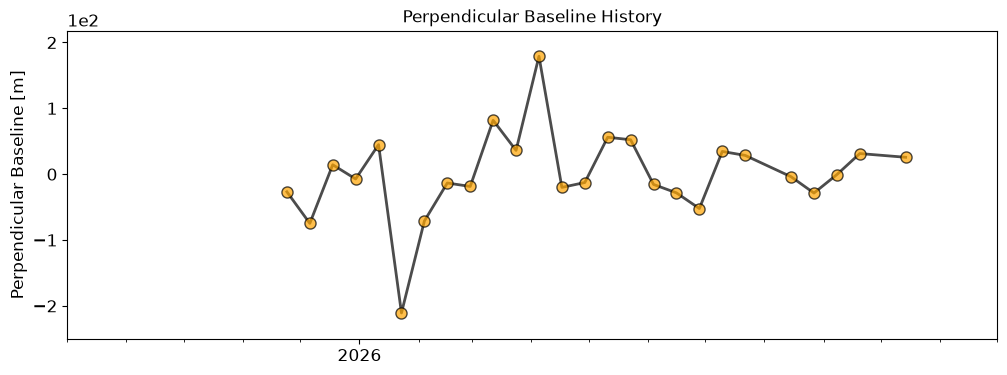

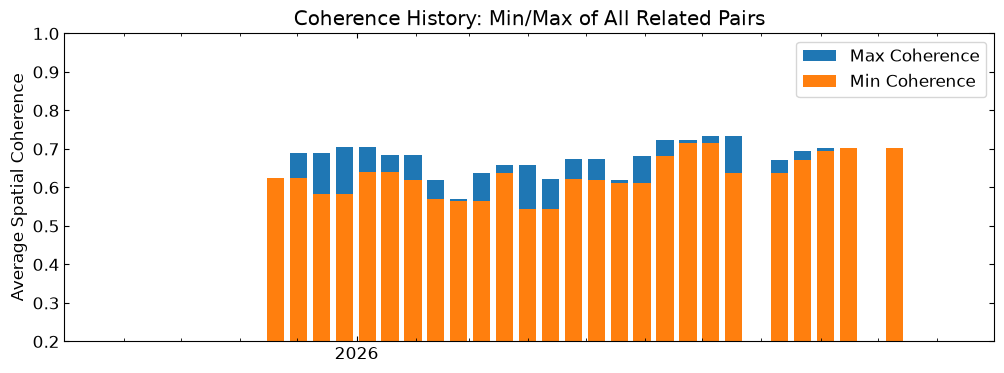

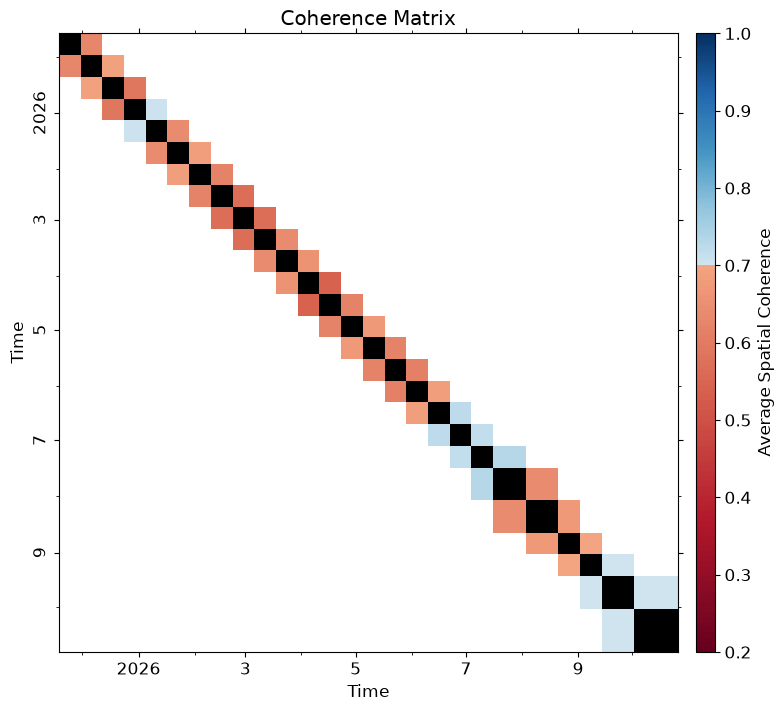

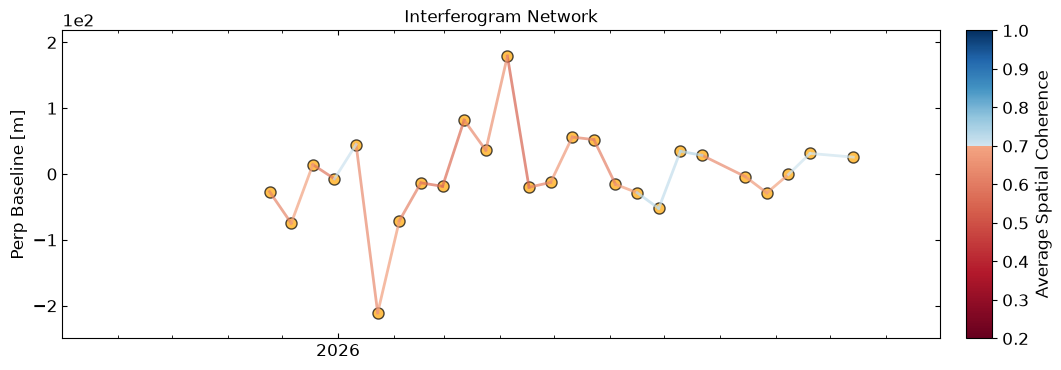

In [40]:
plot_network.main('inputs/ifgramStack.h5 -t smallbaselineApp.cfg --figsize 12 4'.split())

Note that with the `--nodisplay` argument, the plots won't be displayed but saved as pdf files in the current directory. Running this command creates multiple files as follows:

+ `coherenceSpatialAvg.txt`: A simple text file that provides an overview to the stack and contains the interferogram dates, average coherence temporal and spatial baseline separation.
+ `coherenceMatrix.pdf`: Shows the avergae coherence pairs between all available pairs in the stack.
+ `coherenceHistory.pdf`: Shows for each acquisition, the minimum and maximum average coherence among all pairs involing this acquisition. Useful to identify bad acquisitions, which usually have very low value for the maximum coherence. Those acquisitions should be dropped.
+ `network.pdf`: Displays the network of interferograms on time-baseline coordinates, colorcoded by avergae coherence of the interferograms. Circles represent the acquisition dates and lines represent the interferograms. Solid lines are the interferograms used for time-series analysis and dashed line are the interferograms ignored in the time-series analysis. 

## 4.3 Generate quality masks

Before running the time-series inversion, one may want to looks at average coherence in the stack. To create a map of average spatial coherence use `temporal_average.py`:

calculate the temporal average of coherence in file ./inputs/ifgramStack.h5 ...
[===============>        33%                       ] lines 2140/4284    0s /     0s/opt/miniconda3/envs/opera_app/lib/python3.14/site-packages/mintpy/objects/stack.py:1059: RuntimeWarning: Mean of empty slice
  dmean[r0:r1, :] = np.nanmean(data, axis=0)
[==================================================] lines 4284/4284    0s /     0s
delete exsited file: avgSpatialCoh.h5
create HDF5 file: avgSpatialCoh.h5 with w mode
create dataset /coherence of float32    in size of (4284, 4347)         with compression=None
finished writing to avgSpatialCoh.h5
time used: 00 mins 1.4 secs

view.py avgSpatialCoh.h5 --noverbose


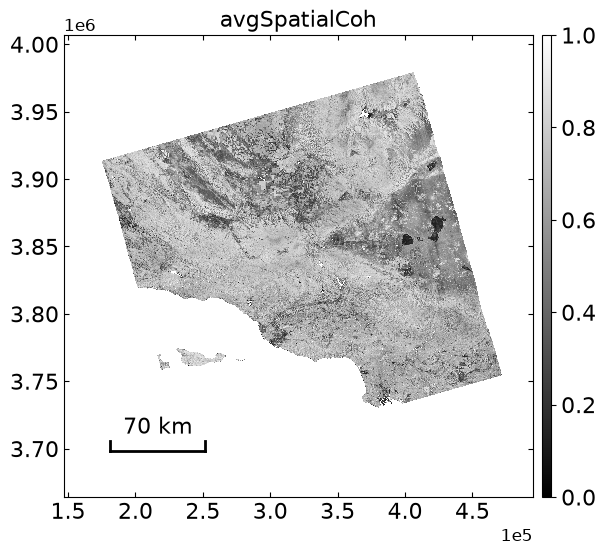

In [41]:
!temporal_average.py ./inputs/ifgramStack.h5 -d coherence -o avgSpatialCoh.h5
plt.rcParams['axes.formatter.limits'] = (0, 0)
view.main('avgSpatialCoh.h5  --noverbose'.split())
# equivalent command in terminal: view.py avgSpatialCoh.h5 --noverbose

Also one may optionally extract the water mask from the geometry file to be used later for masking the time-series results:

input geometry file: inputs/geometryGeo.h5
read inputs/geometryGeo.h5 waterMask
create initial mask with the same size as the input file and all = 1
all pixels with nan value = 0
exclude pixels with zero value
delete exsited file: waterMask.h5
create HDF5 file: waterMask.h5 with w mode
create dataset /mask of bool       in size of (4284, 4347)         with compression=None
finished writing to waterMask.h5
time used: 00 mins 0.1 secs.
view.py waterMask.h5 -c gray --noverbose


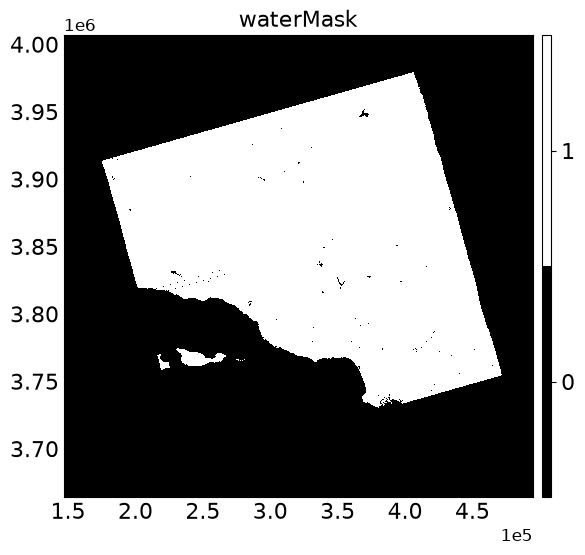

In [42]:
!generate_mask.py inputs/geometryGeo.h5 waterMask --nonzero -o waterMask.h5
view.main('waterMask.h5 -c gray  --noverbose'.split())

The common connected component mask indicates pixels with valid connected component value in all kept interferograms. This is also used to guide the reference point selection.

input ifgramStack file: inputs/ifgramStack.h5
--------------------------------------------------
update mode: ON
1) output file maskConnComp.h5 already exists.
2) output file is NOT newer than input dataset: connectComponent.
run or skip: run.
calculate the common mask of pixels with non-zero connectComponent value
[==================================================] 25/25    0s /     0s
delete exsited file: maskConnComp.h5
create HDF5 file: maskConnComp.h5 with w mode
create dataset /mask of bool       in size of (4284, 4347)         with compression=None
finished writing to maskConnComp.h5
time used: 00 mins 0.7 secs.
view.py maskConnComp.h5 -c gray --noverbose


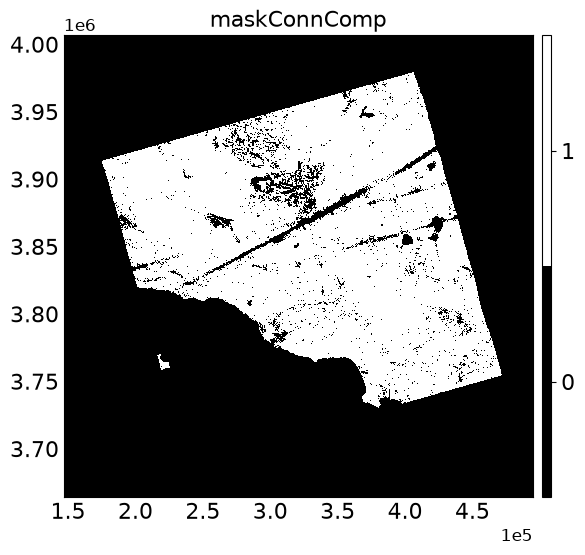

In [43]:
!generate_mask.py  inputs/ifgramStack.h5 --nonzero -o maskConnComp.h5 --update
view.main('maskConnComp.h5 -c gray  --noverbose'.split())

input coherence file: avgSpatialCoh.h5
read avgSpatialCoh.h5
create initial mask with the same size as the input file and all = 1
all pixels with nan value = 0
exclude pixels with value < 0.2
exclude pixels in base file waterMask.h5 with value == 0
delete exsited file: maskSpatialCoh.h5
create HDF5 file: maskSpatialCoh.h5 with w mode
create dataset /mask of bool       in size of (4284, 4347)         with compression=None
finished writing to maskSpatialCoh.h5
time used: 00 mins 0.1 secs.
view.py maskSpatialCoh.h5 -c gray --noverbose


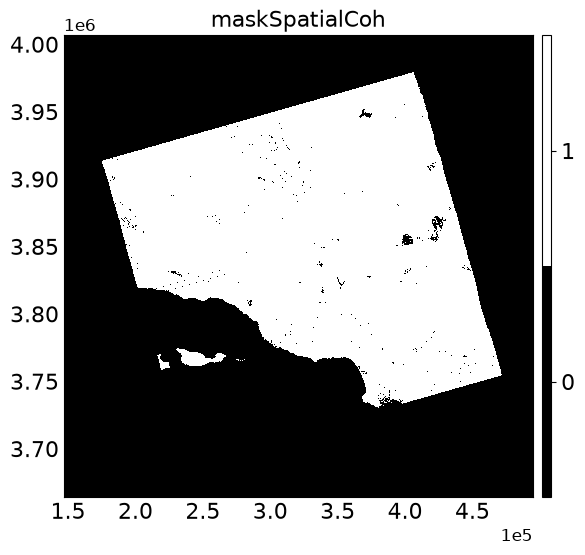

In [44]:
!generate_mask.py  avgSpatialCoh.h5  -m 0.2 --base waterMask.h5 -o maskSpatialCoh.h5
view.main('maskSpatialCoh.h5 -c gray  --noverbose'.split())

## 4.4 Select reference point

The interferometric phase is relative observation by nature. The phases of each unwrapped interferogram are relative with respect to an arbitrary pixel. Therfore we need to reference all interferograms to a common reference pixel.
The step "reference_point" selects a common reference pixel for the stack of interferograms. The default approach of mintpy is to choose a pixel with highest spatial coherence in the stack. Other options include specifying the longitude and latitude of the desired reference pixel or the line and column number of the reference pixel.    

In this example, I specified the location of a GNSS station by latitude and longitude.

There are some guidelines for selecting a reference point based on the prior knowledge of the study area in the [mintpy.reference.*](https://github.com/insarlab/MintPy/blob/1c8e7a1890e95fc9a411f0170dacce47443dc897/src/mintpy/defaults/smallbaselineApp.cfg#L113-L125) section.

In [45]:
!smallbaselineApp.py {cfg_file} --dostep reference_point

MintPy version 1.6.4, date 2026-07-25
--RUN-at-2026-11-18 13:50:16.890144--
Current directory: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy
Run routine processing with smallbaselineApp.py on steps: ['reference_point']
Remaining steps: ['quick_overview', 'correct_unwrap_error', 'invert_network', 'correct_LOD', 'correct_SET', 'correct_ionosphere', 'correct_troposphere', 'deramp', 'correct_topography', 'residual_RMS', 'reference_date', 'velocity', 'geocode', 'google_earth', 'hdfeos5']
--------------------------------------------------
Project name: LosAngeles_NI_A34
Go to work directory: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy
read custom template file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/LosAngeles_NI_A34.txt
update default template based on input custom template
No new option value found, skip updating /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/smallbaselineApp.cfg
read default template f

Running the "reference_step" adds additional attributes "REF_X, REF_Y" and "REF_LON, REF_LAT" to the ifgramStack.h5 file. Because the NISAR GUNW is in the UTM zone 11 projection, MintPy has converted the latitude and longitude of the reference point to UTM Northing and Easting. To see the attributes of the file run info.py:

In [46]:
!info.py inputs/ifgramStack.h5 | egrep 'REF_'

  REF_LAT                                         3784920.0
  REF_LON                                         392200.0
  REF_X                                           3066
  REF_Y                                           2773


Note that reference_point does not change the actual values of the unwrapped phase dataset. However, MintPy takes into account the phase at the reference point while performing the time-series inversion. 

## 4.5 Invert network of interferograms for time-series

In the next step we invert the network of differential unwrapped interferograms to estimate the time-series of unwrapped phase with respect to a reference acquisition date, which by default is the first acquisition. The estimated time-series is converted to distance change from radar to target and is provided in meters.  

In [47]:
!smallbaselineApp.py {cfg_file} --dostep invert_network


MintPy version 1.6.4, date 2026-07-25
--RUN-at-2026-11-18 13:50:21.661441--
Current directory: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy
Run routine processing with smallbaselineApp.py on steps: ['invert_network']
Remaining steps: ['correct_LOD', 'correct_SET', 'correct_ionosphere', 'correct_troposphere', 'deramp', 'correct_topography', 'residual_RMS', 'reference_date', 'velocity', 'geocode', 'google_earth', 'hdfeos5']
--------------------------------------------------
Project name: LosAngeles_NI_A34
Go to work directory: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy
read custom template file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/LosAngeles_NI_A34.txt
update default template based on input custom template
No new option value found, skip updating /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/smallbaselineApp.cfg
read default template file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A

The main product generated after running inver_network step, is timeseries.h5. To see the general content of the file run info.py

In [48]:
!info.py timeseries.h5 --compact

******************** Basic File Info ************************
file name: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/timeseries.h5
file type: timeseries
coordinates : GEO
SNWE: 3664080.0, 4006800.0, 146880.0, 494640.0.

******************** Date Stat Info *************************
Start Date: 20251124
End   Date: 20261014
Number of dates  : 26
STD of datetimes : 0.26 years

******************** HDF5 File Structure ********************
Attributes in / level:
  ALOOKS                                          16
  AZIMUTH_PIXEL_SIZE                              80.0
  CENTER_LINE_UTC                                 47321.999671
  EARTH_RADIUS                                    6371008.8
  END_DATE                                        20261014
  EPSG                                            32611
  FILE_TYPE                                       timeseries
  HEIGHT                                          747000
  LENGTH                                          42

The timeseries file contains three datasets, the time-series which is the interferometric range change for each acquisition relative to the reference acquisition, the "date" dataset which contains the acquisition date for each acquisition and the bperp dataset which contains the timeseries of the perpendicular baseline.  

run view.py in MintPy version 1.6.4, date 2026-07-25
input file is timeseries file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/timeseries.h5 in float32 format
file size in y/x: (4284, 4347)
num of datasets in file timeseries.h5: 26
datasets to exclude (0):
[]
datasets to display (26):
['timeseries-20251124', 'timeseries-20251206', 'timeseries-20251218', 'timeseries-20251230', 'timeseries-20260111', 'timeseries-20260123', 'timeseries-20260204', 'timeseries-20260216', 'timeseries-20260228', 'timeseries-20260312', 'timeseries-20260324', 'timeseries-20260405', 'timeseries-20260417', 'timeseries-20260429', 'timeseries-20260511', 'timeseries-20260523', 'timeseries-20260604', 'timeseries-20260616', 'timeseries-20260628', 'timeseries-20260710', 'timeseries-20260722', 'timeseries-20260815', 'timeseries-20260827', 'timeseries-20260908', 'timeseries-20260920', 'timeseries-20261014']
data   coverage in y/x: (0, 0, 4347, 4284)
subset coverage in y/x: (0, 0, 4347, 4284)
data  

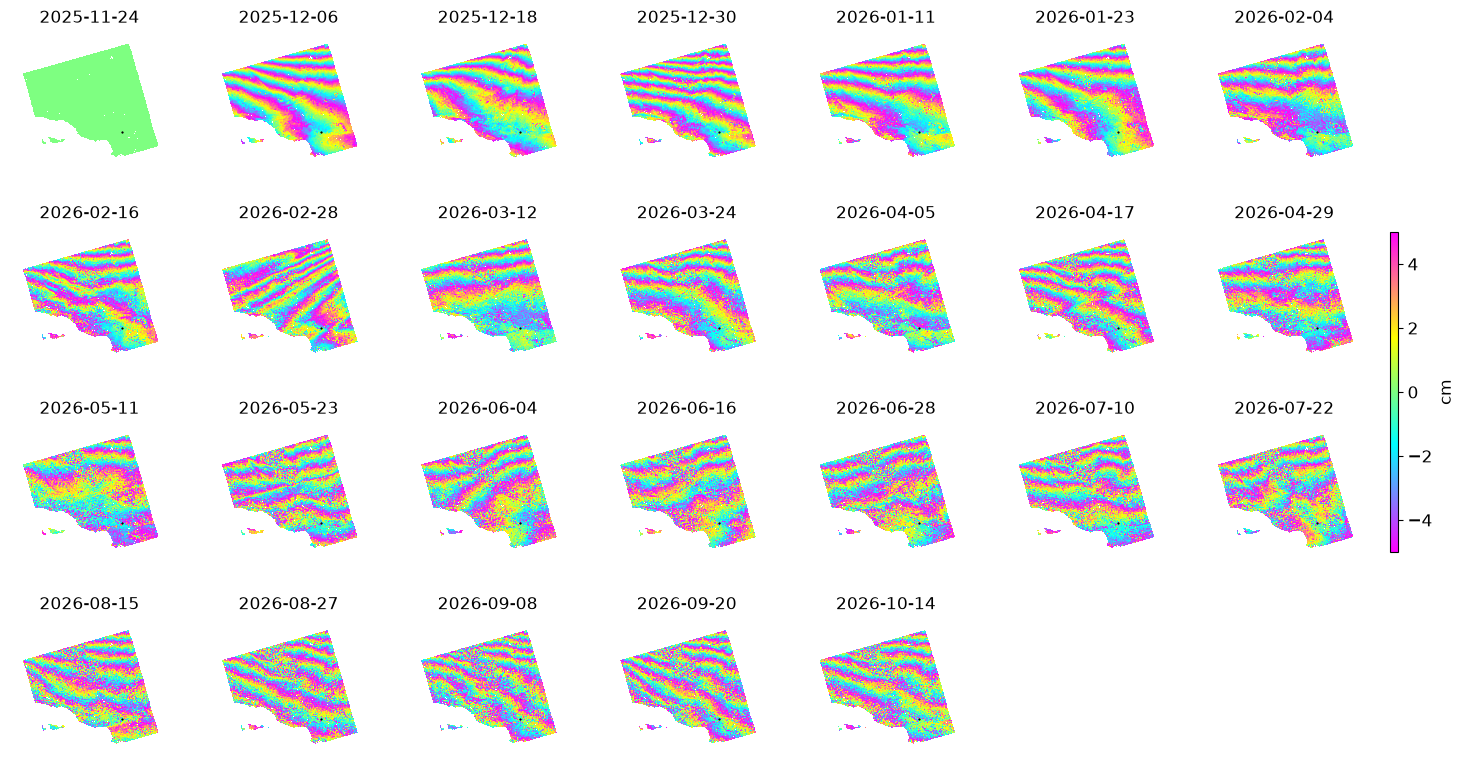

In [49]:
view.main('timeseries.h5 --wrap --wrap-range -5 5 -c cmy --noaxis'.split())
# equivalent command in terminal: view.py timeseries.h5 --wrap --wrap-range -5 5 --noaxis

run view.py in MintPy version 1.6.4, date 2026-07-25
input file is temporalCoherence file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/temporalCoherence.h5 in float32 format
file size in y/x: (4284, 4347)
num of datasets in file temporalCoherence.h5: 1
datasets to exclude (0):
[]
datasets to display (1):
['temporalCoherence']
data   coverage in y/x: (0, 0, 4347, 4284)
subset coverage in y/x: (0, 0, 4347, 4284)
data   coverage in lat/lon: (146880.0, 4006800.0, 494640.0, 3664080.0)
subset coverage in lat/lon: (146880.0, 4006800.0, 494640.0, 3664080.0)
------------------------------------------------------------------------
colormap: gray
figure title: temporalCoherence
figure size : [7.6, 6.0]
reading data ...
data    range: [np.float32(0.0), np.float32(1.0)] 1
display range: [0.0, 1.0] 1
display data in transparency: 1.0
plot in geo-coordinate
plotting data as image via matplotlib.pyplot.imshow ...
plot scale bar: [0.2, 0.2, 0.1]
plot reference point
showing ...


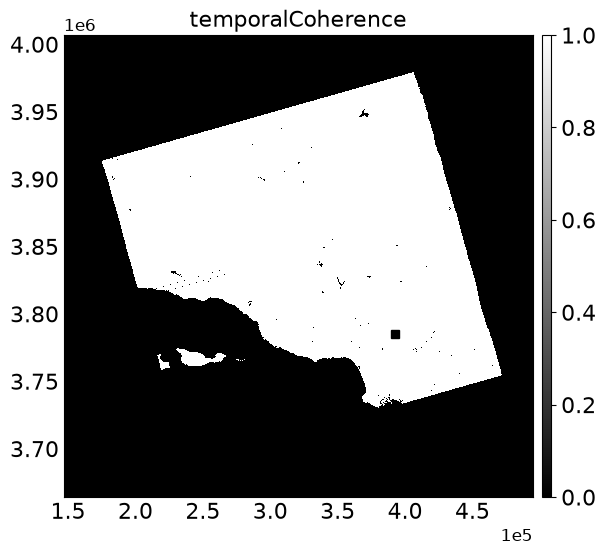

In [50]:
view.main('temporalCoherence.h5 -c gray -v 0 1'.split())


<div class="alert alert-warning">
<b>Question:</b> 
Why the temporal coherence here is so high, i.e. one for all pixels on land?
</div>

## 4.6 Correct ionospheric delays

Correct ionospheric delays using the NISAR GUNW ionospheric delay layer, which is calculated using the split-spectrum technique.

In [51]:
!smallbaselineApp.py {cfg_file} --dostep correct_ionosphere

MintPy version 1.6.4, date 2026-07-25
--RUN-at-2026-11-18 13:50:37.556989--
Current directory: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy
Run routine processing with smallbaselineApp.py on steps: ['correct_ionosphere']
Remaining steps: ['correct_troposphere', 'deramp', 'correct_topography', 'residual_RMS', 'reference_date', 'velocity', 'geocode', 'google_earth', 'hdfeos5']
--------------------------------------------------
Project name: LosAngeles_NI_A34
Go to work directory: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy
read custom template file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/LosAngeles_NI_A34.txt
update default template based on input custom template
No new option value found, skip updating /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/smallbaselineApp.cfg
read default template file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/smallbaselineApp.cfg


***************

Now we can view the estimated ionospheric correction for each date relative to the reference date.

run view.py in MintPy version 1.6.4, date 2026-07-25
input file is timeseries file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/ion.h5 in float32 format
file size in y/x: (4284, 4347)
num of datasets in file ion.h5: 26
datasets to exclude (0):
[]
datasets to display (26):
['timeseries-20251124', 'timeseries-20251206', 'timeseries-20251218', 'timeseries-20251230', 'timeseries-20260111', 'timeseries-20260123', 'timeseries-20260204', 'timeseries-20260216', 'timeseries-20260228', 'timeseries-20260312', 'timeseries-20260324', 'timeseries-20260405', 'timeseries-20260417', 'timeseries-20260429', 'timeseries-20260511', 'timeseries-20260523', 'timeseries-20260604', 'timeseries-20260616', 'timeseries-20260628', 'timeseries-20260710', 'timeseries-20260722', 'timeseries-20260815', 'timeseries-20260827', 'timeseries-20260908', 'timeseries-20260920', 'timeseries-20261014']
data   coverage in y/x: (0, 0, 4347, 4284)
subset coverage in y/x: (0, 0, 4347, 4284)
data   coverage in l

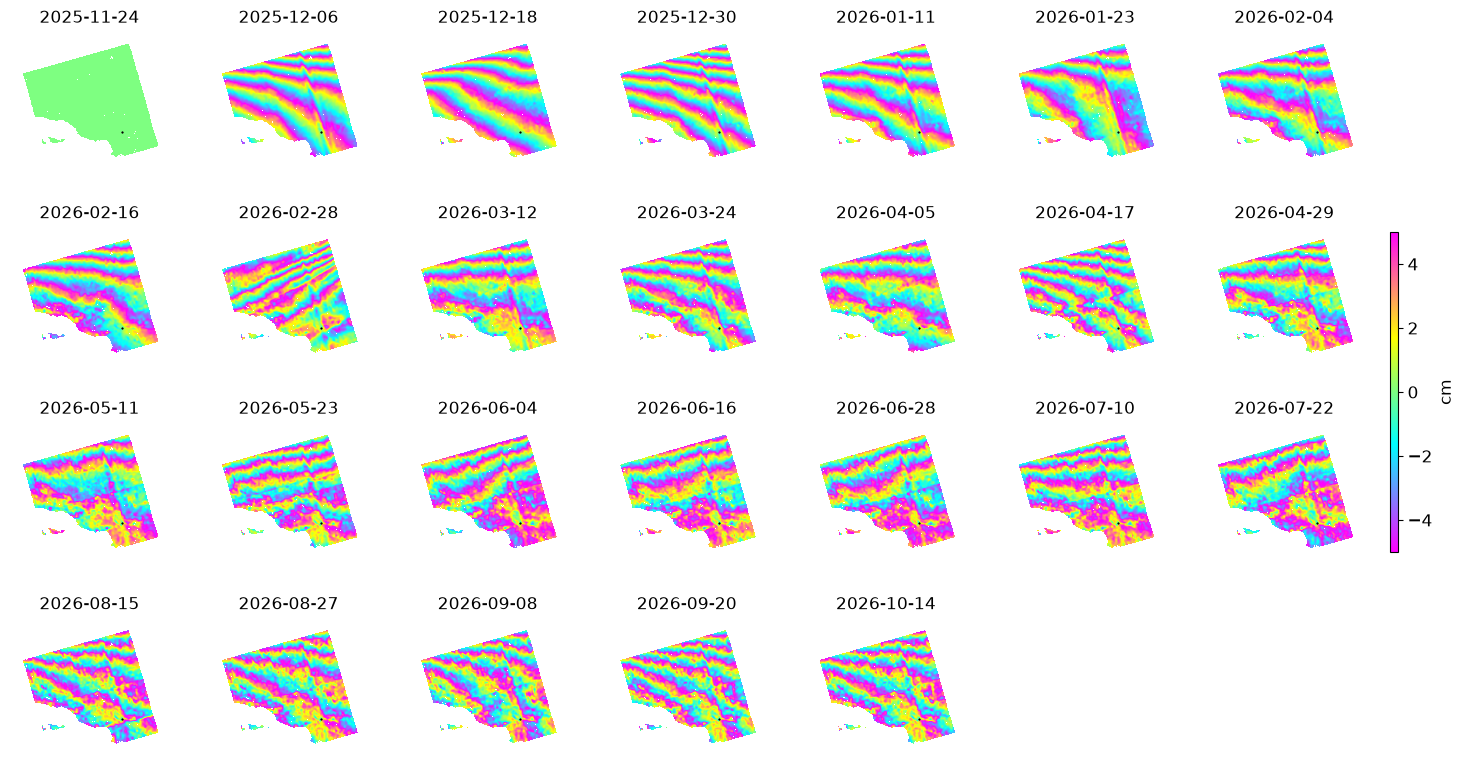

In [52]:
view.main('ion.h5 --wrap --wrap-range -5 5 -c cmy --noaxis'.split())

run view.py in MintPy version 1.6.4, date 2026-07-25
input file is timeseries file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/timeseries_ion.h5 in float32 format
file size in y/x: (4284, 4347)
num of datasets in file timeseries_ion.h5: 26
datasets to exclude (0):
[]
datasets to display (26):
['timeseries-20251124', 'timeseries-20251206', 'timeseries-20251218', 'timeseries-20251230', 'timeseries-20260111', 'timeseries-20260123', 'timeseries-20260204', 'timeseries-20260216', 'timeseries-20260228', 'timeseries-20260312', 'timeseries-20260324', 'timeseries-20260405', 'timeseries-20260417', 'timeseries-20260429', 'timeseries-20260511', 'timeseries-20260523', 'timeseries-20260604', 'timeseries-20260616', 'timeseries-20260628', 'timeseries-20260710', 'timeseries-20260722', 'timeseries-20260815', 'timeseries-20260827', 'timeseries-20260908', 'timeseries-20260920', 'timeseries-20261014']
data   coverage in y/x: (0, 0, 4347, 4284)
subset coverage in y/x: (0, 0, 4347, 4284

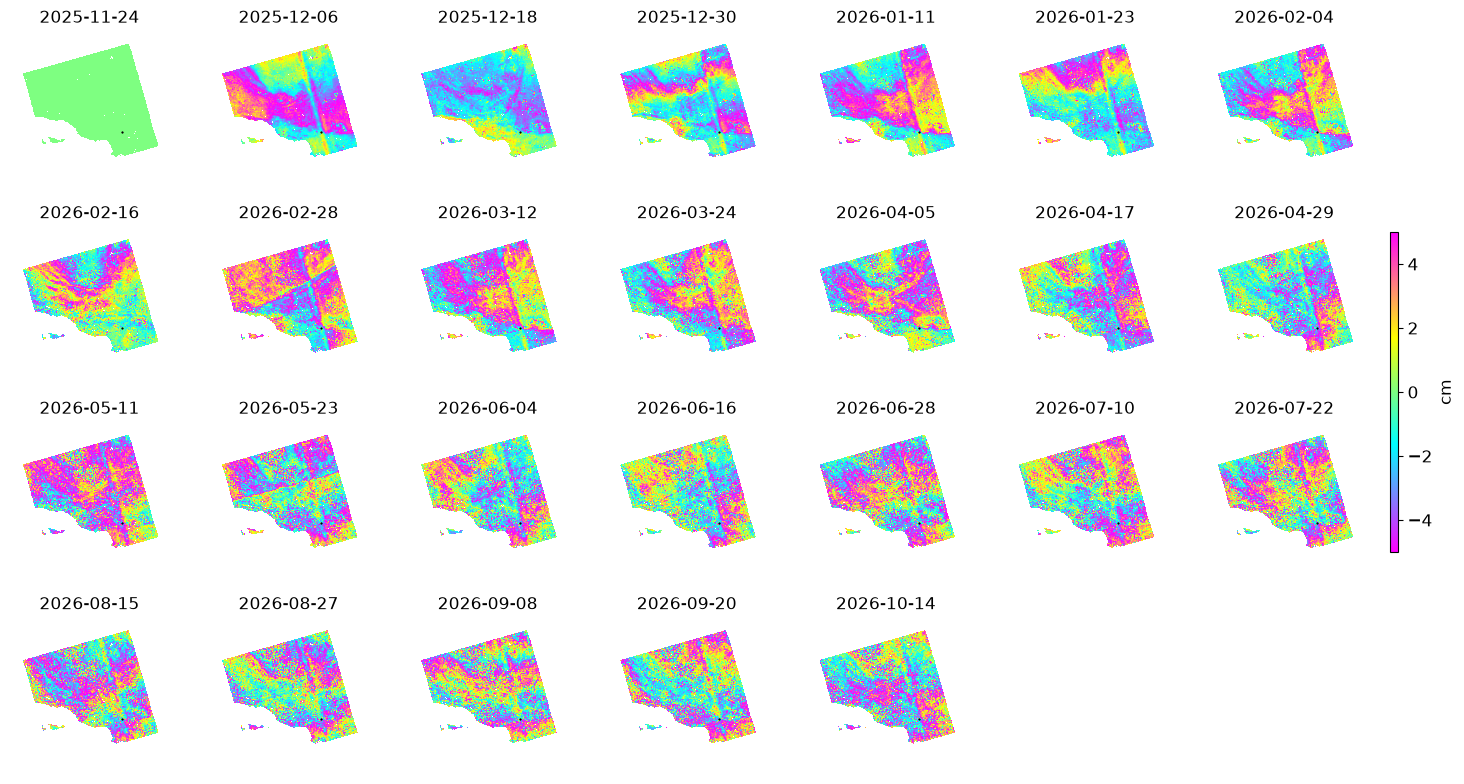

In [53]:
view.main('timeseries_ion.h5 --wrap --wrap-range -5 5 -c cmy --noaxis'.split())

Individual ionospheric phase screens from the first BETA release (CRID X05010) contain banded phase artifacts oriented along the range direction due to mismatched ionosphere filtering. This banding is magnified in interferogram stacks. That problem was fixed in the Preliminary data release (CRID P05023) used here. 

There are some phase artifacts in the along-track direction with the ionospheric correction due to an acquisition issue for some dates in the Preliminary GUNW products.

Check **more information** from NISAR Data User Guide at:
+ https://nisar-docs.asf.alaska.edu/
+ https://nisar-docs.asf.alaska.edu/product-known-issues/

![](docs/banded_phase_artifacts.png)

## 4.7 Correct tropospheric delays

Correct tropospheric delays using [OPERA level-4 TROPO products](https://www.earthdata.nasa.gov/news/nasas-opera-project-releases-troposphere-zenith-radar-delays-dataset). The TROPO product uses high-resolution data from the ECMWF HRES weather model as inputs to compute multi-layer tropospheric corrections, which account for both hydrostatic and wet atmospheric delays from the surface to the top of the troposphere. The OPERA TROPO zenith total delay products are calculated from the same input data with the same software as the NISAR GUNW tropospheric layers, but the OPERA products are provided for each date while the NISAR corrections are the difference between the two dates. The OPERA products are easier to use in MintPy.

In [54]:
!smallbaselineApp.py {cfg_file} --dostep correct_troposphere


MintPy version 1.6.4, date 2026-07-25
--RUN-at-2026-11-18 13:51:00.255017--
Current directory: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy
Run routine processing with smallbaselineApp.py on steps: ['correct_troposphere']
Remaining steps: ['deramp', 'correct_topography', 'residual_RMS', 'reference_date', 'velocity', 'geocode', 'google_earth', 'hdfeos5']
--------------------------------------------------
Project name: LosAngeles_NI_A34
Go to work directory: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy
read custom template file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/LosAngeles_NI_A34.txt
update default template based on input custom template
No new option value found, skip updating /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/smallbaselineApp.cfg
read default template file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/smallbaselineApp.cfg


******************** step - correct_t

Now we can view the time series after applying both the ionospheric and tropospheric corrections.

run view.py in MintPy version 1.6.4, date 2026-07-25
input file is timeseries file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/timeseries_ion_OPERA.h5 in float32 format
file size in y/x: (4284, 4347)
num of datasets in file timeseries_ion_OPERA.h5: 26
datasets to exclude (0):
[]
datasets to display (26):
['timeseries-20251124', 'timeseries-20251206', 'timeseries-20251218', 'timeseries-20251230', 'timeseries-20260111', 'timeseries-20260123', 'timeseries-20260204', 'timeseries-20260216', 'timeseries-20260228', 'timeseries-20260312', 'timeseries-20260324', 'timeseries-20260405', 'timeseries-20260417', 'timeseries-20260429', 'timeseries-20260511', 'timeseries-20260523', 'timeseries-20260604', 'timeseries-20260616', 'timeseries-20260628', 'timeseries-20260710', 'timeseries-20260722', 'timeseries-20260815', 'timeseries-20260827', 'timeseries-20260908', 'timeseries-20260920', 'timeseries-20261014']
data   coverage in y/x: (0, 0, 4347, 4284)
subset coverage in y/x: (0, 0

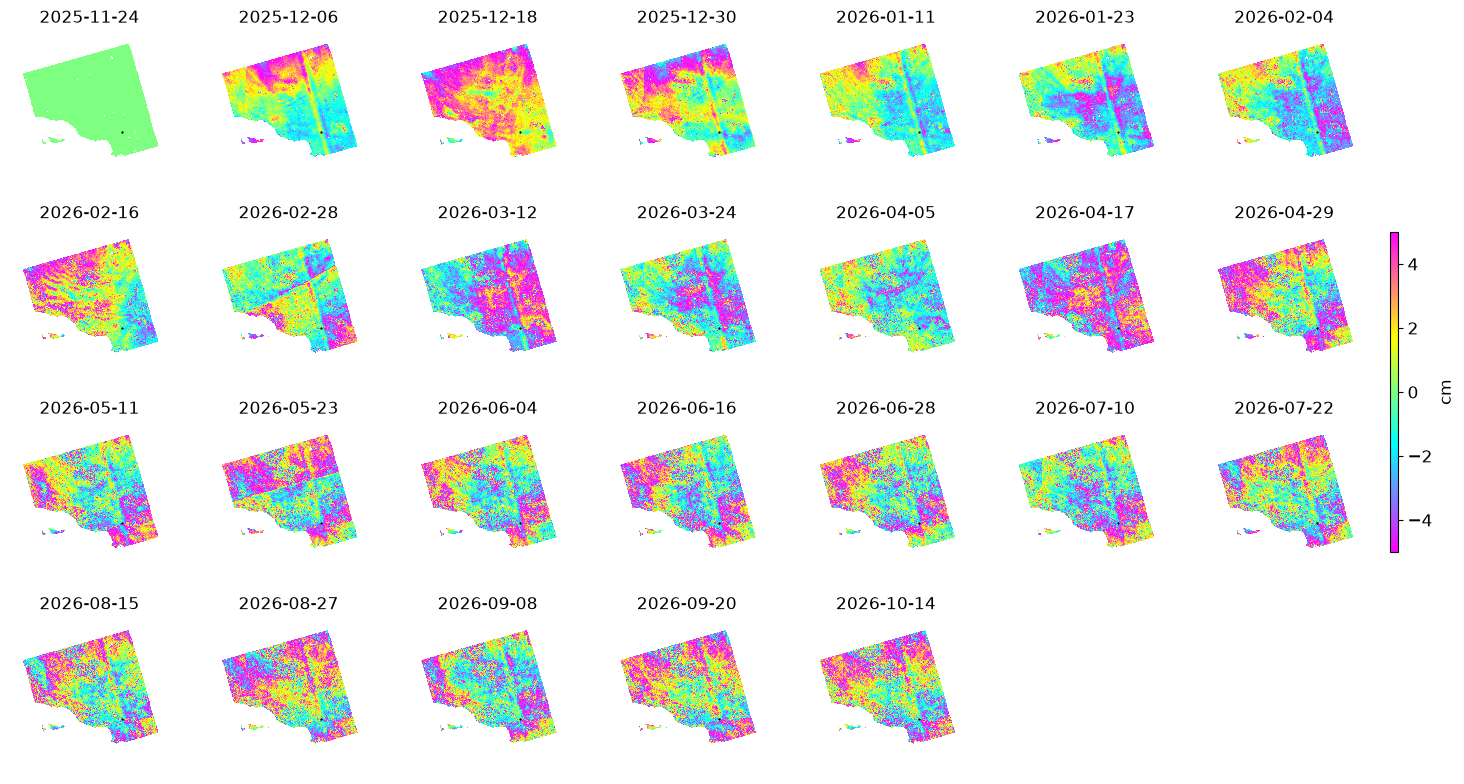

In [55]:
view.main('timeseries_ion_OPERA.h5 --wrap --wrap-range -5 5 -c cmy --noaxis'.split())

run view.py in MintPy version 1.6.4, date 2026-07-25
input file is timeseries file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/inputs/OPERA.h5 in float32 format
file size in y/x: (4284, 4347)
num of datasets in file OPERA.h5: 26
datasets to exclude (0):
[]
datasets to display (26):
['timeseries-20251124', 'timeseries-20251206', 'timeseries-20251218', 'timeseries-20251230', 'timeseries-20260111', 'timeseries-20260123', 'timeseries-20260204', 'timeseries-20260216', 'timeseries-20260228', 'timeseries-20260312', 'timeseries-20260324', 'timeseries-20260405', 'timeseries-20260417', 'timeseries-20260429', 'timeseries-20260511', 'timeseries-20260523', 'timeseries-20260604', 'timeseries-20260616', 'timeseries-20260628', 'timeseries-20260710', 'timeseries-20260722', 'timeseries-20260815', 'timeseries-20260827', 'timeseries-20260908', 'timeseries-20260920', 'timeseries-20261014']
input reference date: timeseries-20251124
data   coverage in y/x: (0, 0, 4347, 4284)
subset cov

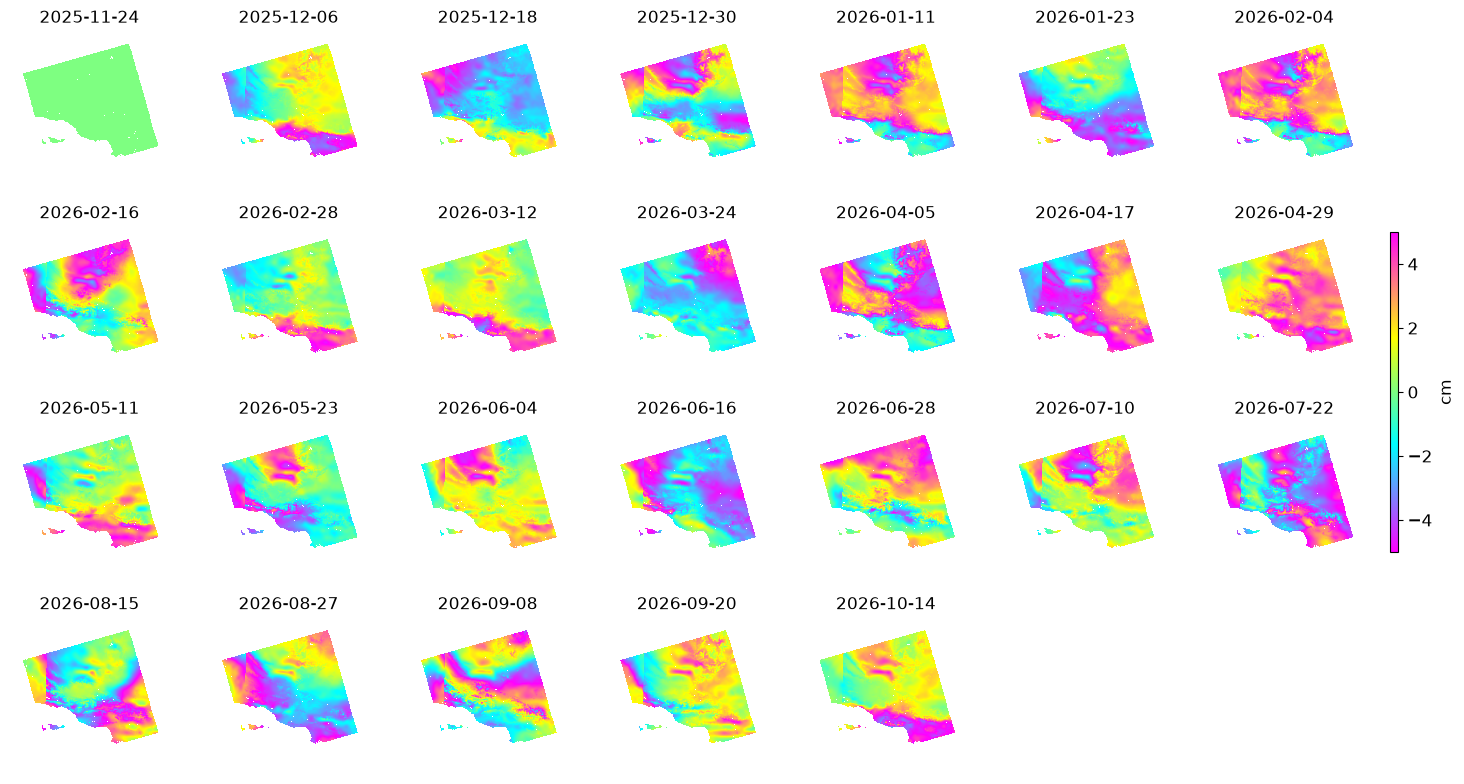

In [56]:
view.main('./inputs/OPERA.h5 --ref-date 20251124 --wrap --wrap-range -5 5 -c cmy --noaxis'.split())

## 4.8 Time-series to velocity

The ground deformation caused by many geophysical or anthropogenic processes are linear at first order approximation. Therefore it is common to estimate the rate of the ground deformation which is the slope of linear fit to the time-series. The step "velocity" estimates the rate of the displacement. 

In [57]:
!smallbaselineApp.py {cfg_file} --dostep velocity


MintPy version 1.6.4, date 2026-07-25
--RUN-at-2026-11-18 13:51:11.000241--
Current directory: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy
Run routine processing with smallbaselineApp.py on steps: ['velocity']
Remaining steps: ['geocode', 'google_earth', 'hdfeos5']
--------------------------------------------------
Project name: LosAngeles_NI_A34
Go to work directory: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy
read custom template file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/LosAngeles_NI_A34.txt
update default template based on input custom template
No new option value found, skip updating /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/smallbaselineApp.cfg
read default template file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/smallbaselineApp.cfg


******************** step - velocity ********************

timeseries2velocity.py /Users/fielding/Downloads/NISAR_training/Los

We can view the velocity fit for all the pixels in the frame. The black square is the reference point.

run view.py in MintPy version 1.6.4, date 2026-07-25
input file is velocity file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/velocity.h5 in float32 format
file size in y/x: (4284, 4347)
input dataset: "['velocity']"
turning glob search OFF for velocity file
num of datasets in file velocity.h5: 5
datasets to exclude (0):
[]
datasets to display (1):
['velocity']
data   coverage in y/x: (0, 0, 4347, 4284)
subset coverage in y/x: (0, 0, 4347, 4284)
data   coverage in lat/lon: (146880.0, 4006800.0, 494640.0, 3664080.0)
subset coverage in lat/lon: (146880.0, 4006800.0, 494640.0, 3664080.0)
------------------------------------------------------------------------
area exceed 2000 pixels, turn off default DEM contour display
colormap: RdBu_r
figure title: velocity
read mask from file: maskTempCoh.h5
reading data ...
masking data
data    range: [np.float32(-25.684336), np.float32(7.1043415)] cm/mon
display range: [-2.5, 2.5] cm/mon
reading DEM: geometryGeo.h5 ...
display d

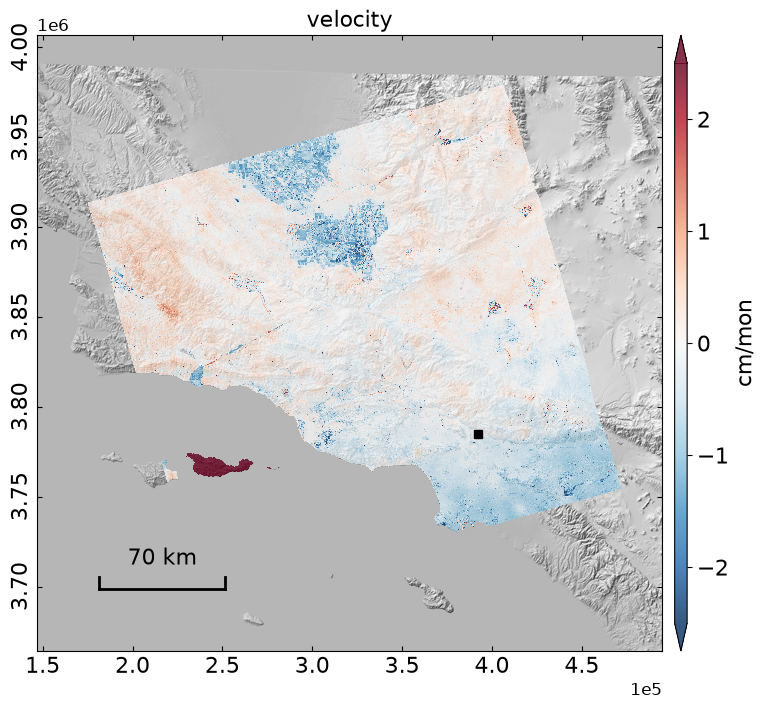

In [58]:
opt = '--dem ./inputs/geometryGeo.h5 --shade-exag 0.05 --dem-nocontour -v -2.5 2.5 --ylabel-rot 90 --figsize 10 8 -c RdBu_r -u cm/month  '
view.main(f'velocity.h5 velocity {opt}'.split())

This next view zooms into the area of Los Angeles.

run view.py in MintPy version 1.6.4, date 2026-07-25
input file is velocity file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/velocity.h5 in float32 format
file size in y/x: (4284, 4347)
input dataset: "['velocity']"
turning glob search OFF for velocity file
num of datasets in file velocity.h5: 5
datasets to exclude (0):
[]
datasets to display (1):
['velocity']
data   coverage in y/x: (0, 0, 4347, 4284)
subset coverage in y/x: (2600, 2700, 3428, 3620)
data   coverage in lat/lon: (146880.0, 4006800.0, 494640.0, 3664080.0)
subset coverage in lat/lon: (354880.0, 3790800.0, 421120.0, 3717200.0)
------------------------------------------------------------------------
colormap: RdBu_r
figure title: velocity_sub
read mask from file: maskSpatialCoh.h5
reading data ...
masking data
data    range: [np.float32(-14.441344), np.float32(3.9893594)] cm/mon
display range: [-15.0, 15.0] cm/mon
reading DEM: geometryGeo.h5 ...
display data in transparency: 0.8
plot in geo-coordinate

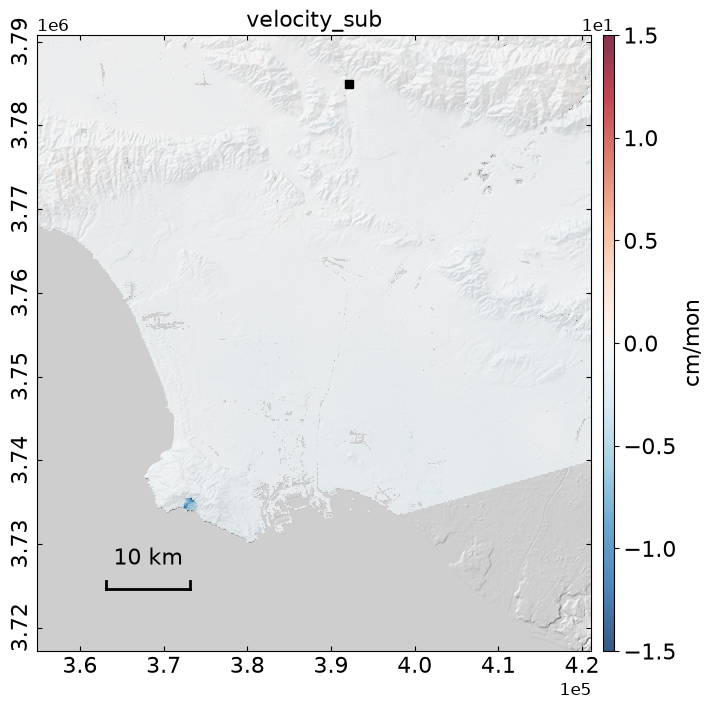

In [59]:
opt = '--dem ./inputs/geometryGeo.h5 --shade-exag 0.05 --dem-nocontour -v -15 15 --ylabel-rot 90 --figsize 10 8 -c RdBu_r -u cm/month  '
opt += '--sub-x 2600 3428 --sub-y 2700 3620 -m maskSpatialCoh.h5'
view.main(f'velocity.h5 velocity {opt}'.split())


<div class="alert alert-info">
<b>Note:</b> 
Negative values indicates that target is moving away from the radar (i.e., subsidence in case of vertical deformation or west for horizontal displacements on this ascending track).
Positive values indicates that target is moving towards the radar (i.e., uplift in case of vertical deformation or east for horizontal).
</div>

**Obvious features in the estimated velocity map:**

1) The strongest signal is **rapid landslide motion** on the Palos Verdes peninsula south of Los Angeles.

2) The Palos Verdes landslide complex is moving mostly south, but somewhat to the west especially in the southwest corner, so the displacement in the ascending track line-of-sight (LOS) direction is negative. The north edge or head of the landslide is moving downward so also negative. The LOS displacements is not the full rate of motion of the landslide.

3) For this short NISAR time span, LOS rates in early 2026 are on the order of 10-15 **cm/month**, much faster than the rates before the end of 2022 (Handwerger, et al., 2022), because the landslide motion accelerated due to heavy rainfall in the wet seasons of 2022-2023 and 2023-2024.


**Relevant references:**
+ Handwerger, A. L., E. J. Fielding, S. S. Sangha, and D. P. S. Bekaert (2022), Landslide Sensitivity and Response to Precipitation Changes in Wet and Dry Climates, Geophysical Research Letters, 49(13), doi:10.1029/2022gl099499.


The estimated velocity also comes with an expression of unecrtainty which is simply based on the goodness of fit while fitting a linear model to the time-series. This quantity is saved in "velocity.h5" under the velocityStd dataset. 

run view.py in MintPy version 1.6.4, date 2026-07-25
input file is velocity file: /Users/fielding/Downloads/NISAR_training/LosAngeles_NI_A34/mintpy/velocity.h5 in float32 format
file size in y/x: (4284, 4347)
input dataset: "['velocityStd']"
turning glob search OFF for velocity file
num of datasets in file velocity.h5: 5
datasets to exclude (0):
[]
datasets to display (1):
['velocityStd']
data   coverage in y/x: (0, 0, 4347, 4284)
subset coverage in y/x: (0, 0, 4347, 4284)
data   coverage in lat/lon: (146880.0, 4006800.0, 494640.0, 3664080.0)
subset coverage in lat/lon: (146880.0, 4006800.0, 494640.0, 3664080.0)
------------------------------------------------------------------------
colormap: RdBu_r
figure title: velocityStd
figure size : [7.6, 6.0]
read mask from file: maskSpatialCoh.h5
reading data ...
masking data
data    range: [np.float32(0.0), np.float32(1.3560305)] cm/mon
display range: [0.0, 0.5] cm/mon
display data in transparency: 1.0
plot in geo-coordinate
plotting data as 

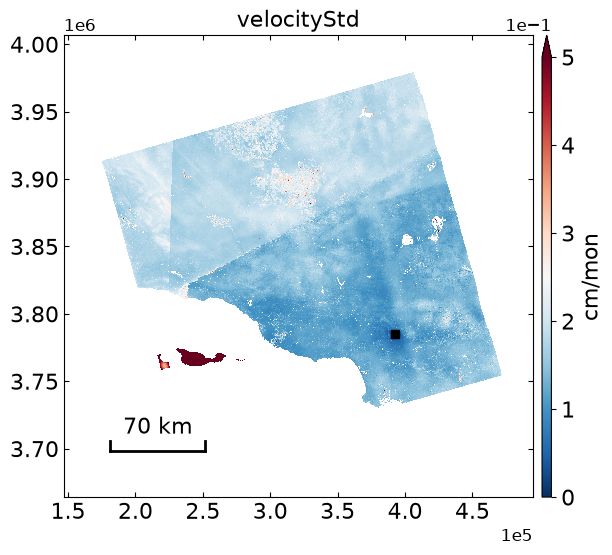

In [60]:
view.main('velocity.h5 velocityStd -u cm/mon -v 0 0.5 -c RdBu_r -m maskSpatialCoh.h5'.split())

The estimated standard deviation only represents the goodness of fit and can be biased or maybe under-estimating the actual uncertainty of the product. However, the spatial pattern of the estimated standard deviation is interesting and clearly shows the spatial correltion of noise in the time-series. The uncertainty is distance dependent and increases with increasing distance between pixels. This map shows the uncertainty for each pixel relative to the reference pixel. The diagonal line across the frame is likely a strong ionospheric effect in one date that was not completely corrected in the Preliminary NISAR data. The islands offshore have large errors because the phase unwrapping was not correct there.

<div class="alert alert-warning">
<b>Question:</b> 
What are the sources of errors that can potentially increase the uncertainty or bias the estimated velocity at this stage?  
</div>